<a href="https://colab.research.google.com/github/anfegomez2026/workshop3-tdsp-ventas/blob/main/Code/02_Modeling/02_Modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, warnings, itertools
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
warnings.filterwarnings("ignore"); sns.set_style("whitegrid"); plt.rcParams["figure.figsize"] = (12, 4)

URL = "https://docs.google.com/spreadsheets/d/e/2PACX-1vSR7UD5-D1NVWyP8lgQ7R7QaN-FiZX8mkHI3piBLe7h34eYuqX7Kjt111lk1Y_jmQ/pub?gid=1926354761&single=true&output=csv"
df = pd.read_csv(URL)
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
y = df.set_index("Order Date")["Sales"].resample("MS").sum().rename("Sales")
y.index.name = "Month"

train, test = y[:"2016-12-01"], y["2017-01-01":]   # 36 meses de entrenamiento / 12 de prueba
H = len(test)
print("Entrenamiento:", len(train), "meses | Prueba:", H, "meses")

Entrenamiento: 36 meses | Prueba: 12 meses


In [2]:
def metricas(real, pred, y_train, m=12):
    real, pred = np.asarray(real), np.asarray(pred)
    e = real - pred
    escala = np.mean(np.abs(y_train.values[m:] - y_train.values[:-m]))  # error del ingenuo estacional
    return {"MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e**2)),
            "MAPE %": np.mean(np.abs(e / real)) * 100, "MASE": np.mean(np.abs(e)) / escala}

def idx_futuro(y_tr, h):
    return pd.date_range(y_tr.index[-1] + pd.offsets.MonthBegin(1), periods=h, freq="MS")

In [3]:
def m_naive(y_tr, h):        # repite el último mes
    return pd.Series(np.repeat(y_tr.iloc[-1], h), idx_futuro(y_tr, h))

def m_naive_est(y_tr, h):    # repite el mismo mes del año anterior (BASELINE)
    return pd.Series(np.tile(y_tr.iloc[-12:].values, int(np.ceil(h / 12)))[:h], idx_futuro(y_tr, h))

def m_hw_add(y_tr, h):
    fit = ExponentialSmoothing(y_tr, trend="add", seasonal="add", seasonal_periods=12).fit()
    return pd.Series(fit.forecast(h).values, idx_futuro(y_tr, h))

def m_hw_mul(y_tr, h):       # estacionalidad multiplicativa (hallazgo del EDA)
    fit = ExponentialSmoothing(y_tr, trend="add", seasonal="mul", seasonal_periods=12).fit()
    return pd.Series(fit.forecast(h).values, idx_futuro(y_tr, h))

In [4]:
def hacer_sarima(order, sorder, trend="n"):
    def f(y_tr, h):
        res = SARIMAX(np.log(y_tr), order=order, seasonal_order=sorder, trend=trend).fit(disp=False)
        return pd.Series(np.exp(res.forecast(h)).values, idx_futuro(y_tr, h))
    return f

# Búsqueda en grilla sobre log(ventas), D=1 (resultado de las pruebas de estacionariedad)
filas = []
for p, d, q, P, Q in itertools.product([0, 1, 2], [0, 1], [0, 1, 2], [0, 1], [0, 1]):
    tr = "c" if d == 0 else "n"          # con d=0 la constante actúa como drift (crecimiento)
    try:
        r = SARIMAX(np.log(train), order=(p, d, q), seasonal_order=(P, 1, Q, 12), trend=tr).fit(disp=False)
        filas.append({"order": (p, d, q), "seasonal": (P, 1, Q, 12), "trend": tr, "d": d, "AIC": r.aic})
    except Exception:
        pass
grid = pd.DataFrame(filas).sort_values("AIC")
# El AIC solo es comparable con el mismo d → mejor modelo por cada d
mejores = grid.groupby("d").head(1)
display(grid.head(8).round(2))

sarima_cfg = {
    "SARIMA(1,0,0)(1,1,0)12 + drift": ((1, 0, 0), (1, 1, 0, 12), "c"),   # sugerido por ACF/PACF
    "SARIMA(0,1,1)(0,1,1)12 aerolínea": ((0, 1, 1), (0, 1, 1, 12), "n"),  # modelo clásico
}
for _, r in mejores.iterrows():
    sarima_cfg[f"SARIMA auto {r['order']}{r['seasonal'][:3]}12 (d={r['d']})"] = (r["order"], r["seasonal"], r["trend"])
print(list(sarima_cfg))

,order,seasonal,trend,d,AIC
0,"(0, 0, 0)","(0, 1, 0, 12)",c,0,18.16
4,"(0, 0, 1)","(0, 1, 0, 12)",c,0,20.07
24,"(1, 0, 0)","(0, 1, 0, 12)",c,0,20.07
2,"(0, 0, 0)","(1, 1, 0, 12)",c,0,20.14
1,"(0, 0, 0)","(0, 1, 1, 12)",c,0,20.14
60,"(2, 1, 0)","(0, 1, 0, 12)",n,1,20.86
16,"(0, 1, 1)","(0, 1, 0, 12)",n,1,21.73
48,"(2, 0, 0)","(0, 1, 0, 12)",c,0,22.01


['SARIMA(1,0,0)(1,1,0)12 + drift', 'SARIMA(0,1,1)(0,1,1)12 aerolínea', 'SARIMA auto (0, 0, 0)(0, 1, 0)12 (d=0)', 'SARIMA auto (2, 1, 0)(0, 1, 0)12 (d=1)']


In [5]:
def features(idx):
    X = pd.DataFrame(index=idx)
    X["t"] = (idx.year - 2014) * 12 + idx.month - 1            # tendencia
    for mth in range(2, 13):
        X[f"m{mth}"] = (idx.month == mth).astype(int)          # dummies de mes (estacionalidad)
    return X

def m_reg(y_tr, h):          # regresión lineal sobre log: tendencia + estacionalidad
    lr = LinearRegression().fit(features(y_tr.index), np.log(y_tr))
    fut = idx_futuro(y_tr, h)
    return pd.Series(np.exp(lr.predict(features(fut))), fut)

def m_rf(y_tr, h):           # Random Forest con rezago 12, mes y tendencia
    fut = idx_futuro(y_tr, h)
    def X_de(idx):
        X = pd.DataFrame({"t": features(idx)["t"], "mes": idx.month}, index=idx)
        X["lag12"] = [y_tr.get(i - pd.DateOffset(months=12), np.nan) for i in idx]
        return X
    X = X_de(y_tr.index).dropna()
    X["lag12"] = np.log(X["lag12"])
    rf = RandomForestRegressor(n_estimators=500, random_state=42).fit(X, np.log(y_tr.loc[X.index]))
    Xf = X_de(fut); Xf["lag12"] = np.log(Xf["lag12"])
    return pd.Series(np.exp(rf.predict(Xf)), fut)

,Modelo,MAE,RMSE,MAPE %,MASE
0,Holt-Winters multiplicativo,12431.61,16384.23,20.77,1.24
1,Regresión log (tendencia + mes),12796.71,15124.25,22.00,1.28
2,Holt-Winters aditivo,11453.06,12541.07,22.59,1.14
3,Random Forest (lag12 + mes + t),12115.93,14737.82,22.60,1.21
4,"SARIMA auto (0, 0, 0)(0, 1, 0)12 (d=0)",13343.00,17142.65,24.26,1.33
5,"SARIMA(1,0,0)(1,1,0)12 + drift",13418.59,17274.80,24.46,1.34
6,Ingenuo estacional (baseline),15467.89,18985.70,24.52,1.55
7,"SARIMA(0,1,1)(0,1,1)12 aerolínea",14680.84,19007.29,27.64,1.47
8,"SARIMA auto (2, 1, 0)(0, 1, 0)12 (d=1)",15556.96,19440.19,28.67,1.55
9,Ingenuo,39472.57,44191.89,97.32,3.94


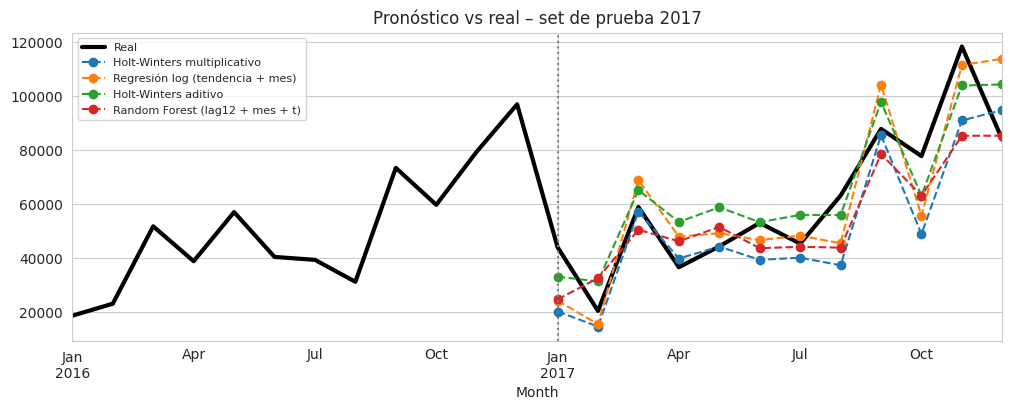

In [6]:
modelos = {"Ingenuo": m_naive, "Ingenuo estacional (baseline)": m_naive_est,
           "Holt-Winters aditivo": m_hw_add, "Holt-Winters multiplicativo": m_hw_mul,
           "Regresión log (tendencia + mes)": m_reg, "Random Forest (lag12 + mes + t)": m_rf}
for nombre, (o, so, tr) in sarima_cfg.items():
    modelos[nombre] = hacer_sarima(o, so, tr)

preds, filas = {}, []
for nombre, f in modelos.items():
    preds[nombre] = f(train, H)
    filas.append({"Modelo": nombre, **metricas(test, preds[nombre], train)})
tabla = pd.DataFrame(filas).sort_values("MAPE %").reset_index(drop=True)
display(tabla.round(2))

ax = y["2016-01-01":].plot(color="black", lw=3, label="Real")
for nombre in tabla["Modelo"].head(4):
    preds[nombre].plot(ax=ax, ls="--", marker="o", label=nombre)
ax.axvline(test.index[0], color="gray", ls=":"); ax.set_title("Pronóstico vs real – set de prueba 2017")
ax.legend(fontsize=8); plt.show()

In [7]:
origenes, h_bt = [36, 39, 42, 45], 3     # entrena hasta dic-16, mar-17, jun-17 y sep-17; pronostica 3 meses
bt = []
for nombre, f in modelos.items():
    errs = []
    for o in origenes:
        y_tr, y_te = y.iloc[:o], y.iloc[o:o + h_bt]
        p = f(y_tr, h_bt)
        errs.append(np.mean(np.abs((y_te.values - p.values) / y_te.values)) * 100)
    bt.append({"Modelo": nombre, "MAPE backtest %": np.mean(errs)})
tabla = tabla.merge(pd.DataFrame(bt), on="Modelo")
display(tabla.round(2))

,Modelo,MAE,RMSE,MAPE %,MASE,MAPE backtest %
0,Holt-Winters multiplicativo,12431.61,16384.23,20.77,1.24,20.81
1,Regresión log (tendencia + mes),12796.71,15124.25,22.00,1.28,23.22
2,Holt-Winters aditivo,11453.06,12541.07,22.59,1.14,19.81
3,Random Forest (lag12 + mes + t),12115.93,14737.82,22.60,1.21,23.08
4,"SARIMA auto (0, 0, 0)(0, 1, 0)12 (d=0)",13343.00,17142.65,24.26,1.33,24.47
5,"SARIMA(1,0,0)(1,1,0)12 + drift",13418.59,17274.80,24.46,1.34,24.08
6,Ingenuo estacional (baseline),15467.89,18985.70,24.52,1.55,24.52
7,"SARIMA(0,1,1)(0,1,1)12 aerolínea",14680.84,19007.29,27.64,1.47,25.72
8,"SARIMA auto (2, 1, 0)(0, 1, 0)12 (d=1)",15556.96,19440.19,28.67,1.55,30.87
9,Ingenuo,39472.57,44191.89,97.32,3.94,65.41


Mejor SARIMA: SARIMA auto (0, 0, 0)(0, 1, 0)12 (d=0)
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.1789      0.070      2.550      0.011       0.041       0.316
sigma2         0.1056      0.033      3.155      0.002       0.040       0.171

Ljung-Box (p > 0.05 = residuos sin autocorrelación = ruido blanco):


,lb_stat,lb_pvalue
6,3.0381,0.8040
12,8.1547,0.7729


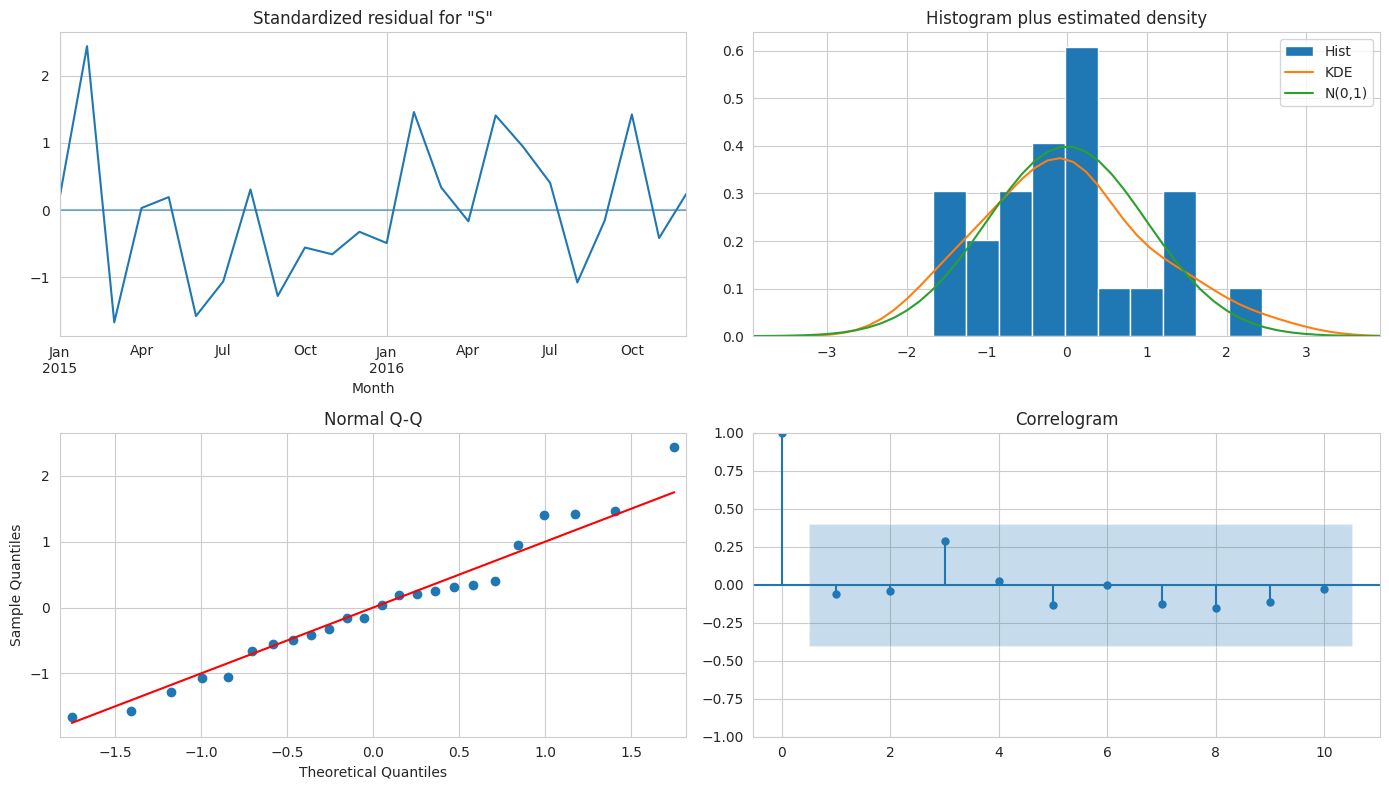

In [8]:
mejor_sarima = tabla[tabla["Modelo"].isin(sarima_cfg)].iloc[0]["Modelo"]
o, so, tr = sarima_cfg[mejor_sarima]
res = SARIMAX(np.log(train), order=o, seasonal_order=so, trend=tr).fit(disp=False)
print("Mejor SARIMA:", mejor_sarima)
print(res.summary().tables[1])
print("\nLjung-Box (p > 0.05 = residuos sin autocorrelación = ruido blanco):")
display(acorr_ljungbox(res.resid[13:], lags=[6, 12], return_df=True).round(4))
res.plot_diagnostics(figsize=(14, 8), lags=10); plt.tight_layout(); plt.show()

Modelo seleccionado: Holt-Winters multiplicativo


,Pronostico
Month,
2018-01-01,33566.0
2018-02-01,20237.0
2018-03-01,69241.0
2018-04-01,46547.0
2018-05-01,53122.0
2018-06-01,52167.0
2018-07-01,49764.0
2018-08-01,54741.0
2018-09-01,102456.0


Total pronosticado 2018: 777728 | Real 2017: 733215


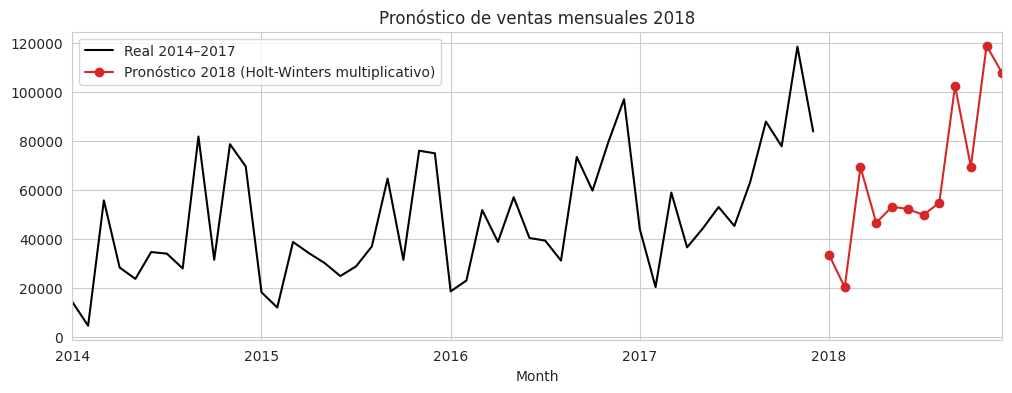

In [9]:
mejor = tabla.iloc[0]["Modelo"]
print("Modelo seleccionado:", mejor)
salida = modelos[mejor](y, 12).rename("Pronostico").to_frame()

if mejor in sarima_cfg:   # intervalos de predicción al 95%
    o, so, tr = sarima_cfg[mejor]
    res_final = SARIMAX(np.log(y), order=o, seasonal_order=so, trend=tr).fit(disp=False)
    ci = np.exp(res_final.get_forecast(12).conf_int(alpha=0.05))
    salida["Limite_inferior"], salida["Limite_superior"] = ci.iloc[:, 0].values, ci.iloc[:, 1].values
    res_final.save("modelo_final_sarima.pkl")

salida.index.name = "Month"
display(salida.round(0))
print("Total pronosticado 2018:", round(salida["Pronostico"].sum()), "| Real 2017:", round(y["2017"].sum()))

ax = y.plot(color="black", label="Real 2014–2017")
salida["Pronostico"].plot(ax=ax, color="tab:red", marker="o", label=f"Pronóstico 2018 ({mejor})")
if "Limite_inferior" in salida:
    ax.fill_between(salida.index, salida["Limite_inferior"], salida["Limite_superior"], color="tab:red", alpha=.15, label="IC 95%")
ax.set_title("Pronóstico de ventas mensuales 2018"); ax.legend(); plt.show()

In [10]:
tabla.round(4).to_csv("comparacion_modelos.csv", index=False)
salida.to_csv("pronostico_2018.csv")
train.to_frame().to_csv("train_2014_2016.csv"); test.to_frame().to_csv("test_2017.csv")
pbi = pd.concat([y.rename("Ventas").to_frame().assign(Tipo="Real"),
                 salida[["Pronostico"]].rename(columns={"Pronostico": "Ventas"}).assign(Tipo="Pronóstico")])
pbi.index.name = "Mes"; pbi.to_csv("ventas_real_y_pronostico.csv")

from google.colab import files
import os
for f in ["comparacion_modelos.csv", "pronostico_2018.csv", "train_2014_2016.csv", "test_2017.csv",
          "ventas_real_y_pronostico.csv", "modelo_final_sarima.pkl"]:
    if os.path.exists(f): files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>